# 00 — Toronto v2 environment check

## Purpose

This notebook verifies that the Python environment required for the Toronto heat-conditioned accessibility workflow is working correctly **before any spatial processing begins**.

The Toronto v2 workflow will rely on:

- **VoxCity** for urban-form and voxel preparation;
- **GDAL / rasterio** for raster processing;
- **GeoPandas / Shapely** for vector spatial data;
- **OSMnx / NetworkX** for the pedestrian network;
- **xarray / NumPy / pandas** for gridded and tabular data;
- **matplotlib** for diagnostic visualisation;
- optionally **Google Earth Engine** for some VoxCity data sources.

This notebook should be run with the Jupyter kernel:

**Python 3.12 - VoxCity**

It does not perform any analysis or download study data.

## 1. Confirm the Python environment

The first check confirms which Python executable and version the notebook is actually using.

VoxCity 1.7.0 requires Python below 3.14, so this Toronto workflow uses the dedicated Python 3.12 environment.

In [1]:
import sys
import platform

print("Python version :", sys.version)
print("Python executable:", sys.executable)
print("Platform        :", platform.platform())

major, minor = sys.version_info[:2]

if (major, minor) == (3, 12):
    print("\n✓ Correct Python version for the Toronto VoxCity workflow.")
else:
    print(
        "\nWARNING: This notebook was designed for Python 3.12. "
        f"Current version is {major}.{minor}."
    )

Python version : 3.12.15 (main, Oct 13 2026, 16:52:04) [GCC 15.3.0]
Python executable: /users/modjrian/.conda/envs/voxcity312/bin/python
Platform        : Linux-5.14.0-687.54.1.el9_8.x86_64-x86_64-with-glibc2.34

✓ Correct Python version for the Toronto VoxCity workflow.


## 2. Resolve the repository structure

The cleaned Toronto notebooks are expected to live in:

```text
heat-conditioned-accessibility/
└── notebooks_toronto_v02/
```

The code below automatically identifies the repository root when the notebook is launched from that folder.

If the notebook is opened from a different working directory, the root can be set manually.

In [2]:
from pathlib import Path

HERE = Path.cwd().resolve()

if HERE.name == "notebooks_toronto_v02":
    PROJECT_ROOT = HERE.parent
elif (HERE / "notebooks_toronto_v02").exists():
    PROJECT_ROOT = HERE
else:
    # Fallback for the CSC/Roihu repository location.
    PROJECT_ROOT = Path(
        "/scratch/project_2010417/paper3/heat-conditioned-accessibility"
    )

print("Current working directory:", HERE)
print("Project root             :", PROJECT_ROOT)
print("Project root exists      :", PROJECT_ROOT.exists())

Current working directory: /scratch/project_2010417/paper3/heat-conditioned-accessibility/notebooks_toronto_v02
Project root             : /scratch/project_2010417/paper3/heat-conditioned-accessibility
Project root exists      : True


## 3. Define Toronto project folders

Toronto-specific data and outputs are kept separate from the Sevilla PoC so that the two experiments can be reproduced independently.

The suggested structure is:

```text
data/
└── toronto/
    ├── raw/
    ├── interim/
    └── processed/

outputs/
└── toronto/
```

In [3]:
TORONTO_DATA = PROJECT_ROOT / "data" / "toronto"
TORONTO_RAW = TORONTO_DATA / "raw"
TORONTO_INTERIM = TORONTO_DATA / "interim"
TORONTO_PROCESSED = TORONTO_DATA / "processed"

TORONTO_OUTPUTS = PROJECT_ROOT / "outputs" / "toronto"

folders = [
    TORONTO_RAW,
    TORONTO_INTERIM,
    TORONTO_PROCESSED,
    TORONTO_OUTPUTS,
]

for folder in folders:
    folder.mkdir(parents=True, exist_ok=True)

for folder in folders:
    print(f"{folder}  ->  exists={folder.exists()}")

/scratch/project_2010417/paper3/heat-conditioned-accessibility/data/toronto/raw  ->  exists=True
/scratch/project_2010417/paper3/heat-conditioned-accessibility/data/toronto/interim  ->  exists=True
/scratch/project_2010417/paper3/heat-conditioned-accessibility/data/toronto/processed  ->  exists=True
/scratch/project_2010417/paper3/heat-conditioned-accessibility/outputs/toronto  ->  exists=True


## 4. Check GDAL

GDAL is a core geospatial dependency and is also used indirectly by several Python spatial libraries.

A successful import here confirms that the Python 3.12 environment has working GDAL bindings.

In [4]:
from osgeo import gdal

gdal_version = gdal.VersionInfo()

print("GDAL VersionInfo:", gdal_version)
print("✓ GDAL imported successfully.")

GDAL VersionInfo: 3130300
✓ GDAL imported successfully.


## 5. Check VoxCity

VoxCity is central to the urban-form workflow.

This step verifies that the dedicated environment can import VoxCity successfully.

In [5]:
import voxcity

voxcity_version = getattr(
    voxcity,
    "__version__",
    "version not exposed",
)

print("VoxCity version:", voxcity_version)
print("✓ VoxCity imported successfully.")

VoxCity version: 1.7.0
✓ VoxCity imported successfully.


## 6. Check the core geospatial and scientific stack

The following packages are required repeatedly throughout the Toronto workflow.

In [6]:
import importlib

required_packages = [
    "geopandas",
    "shapely",
    "osmnx",
    "networkx",
    "rasterio",
    "xarray",
    "numpy",
    "pandas",
    "matplotlib",
    "scipy",
]

package_status = {}

for package in required_packages:
    try:
        module = importlib.import_module(package)
        version = getattr(
            module,
            "__version__",
            "version not exposed",
        )

        package_status[package] = {
            "status": "OK",
            "version": version,
        }

        print(
            f"{package:12s}  OK   {version}"
        )

    except Exception as exc:
        package_status[package] = {
            "status": "FAIL",
            "version": None,
            "error": str(exc),
        }

        print(
            f"{package:12s}  FAIL  {exc}"
        )

geopandas     OK   1.2.0
shapely       OK   2.2.0
osmnx         OK   2.1.1
networkx      OK   3.7
rasterio      OK   1.5.2
xarray        OK   2026.9.0
numpy         OK   2.5.4
pandas        OK   2.3.3
matplotlib    OK   3.11.2
scipy         OK   1.18.1


## 7. Check optional Google Earth Engine support

VoxCity can use multiple data sources. Some workflows may rely on Google Earth Engine.

At this stage we only check whether the Python package is available. Authentication can be configured later if a selected Toronto data source requires it.

In [7]:
ee_available = False
ee_message = None

try:
    import ee

    ee_available = True
    ee_message = "Earth Engine Python package is installed."
    print("✓", ee_message)

except Exception as exc:
    ee_message = str(exc)
    print("Earth Engine package is not currently available.")
    print("This is not yet a blocking issue.")
    print("Details:", ee_message)

✓ Earth Engine Python package is installed.


## 8. Check key VoxCity imports used later

Importing the specific VoxCity functions now helps catch API or dependency problems before the study-area and urban-form notebooks.

In [8]:
voxcity_api_ok = True
voxcity_api_error = None

try:
    from voxcity.generator import (
        get_voxcity,
        load_voxcity,
        save_voxcity,
        update_voxcity,
    )

    print("✓ VoxCity generator API imported successfully.")

except Exception as exc:
    voxcity_api_ok = False
    voxcity_api_error = str(exc)

    print("VoxCity generator import failed.")
    print("Details:", voxcity_api_error)

✓ VoxCity generator API imported successfully.


## 9. Check plotting and raster write capability

This is a small local smoke test. It does not use Toronto data.

The purpose is simply to confirm that:

- NumPy can create an array;
- matplotlib can render it;
- rasterio can write and reopen a GeoTIFF.

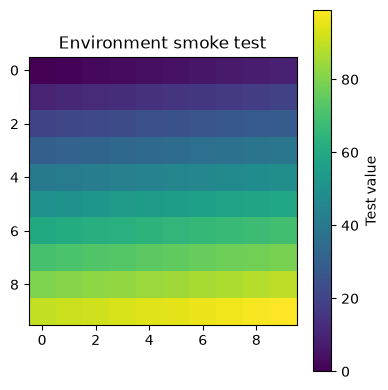

In [9]:
import numpy as np
import matplotlib.pyplot as plt
import rasterio

from rasterio.transform import from_origin

test_array = np.arange(
    100,
    dtype=np.float32,
).reshape(10, 10)

fig, ax = plt.subplots(figsize=(4, 4))

image = ax.imshow(
    test_array,
    origin="upper",
)

ax.set_title("Environment smoke test")
plt.colorbar(
    image,
    ax=ax,
    label="Test value",
)

plt.tight_layout()
plt.show()

In [10]:
smoke_test_path = TORONTO_OUTPUTS / "_environment_test.tif"

transform = from_origin(
    0,
    10,
    1,
    1,
)

with rasterio.open(
    smoke_test_path,
    "w",
    driver="GTiff",
    height=test_array.shape[0],
    width=test_array.shape[1],
    count=1,
    dtype=test_array.dtype,
    crs="EPSG:32617",
    transform=transform,
) as dst:
    dst.write(test_array, 1)

with rasterio.open(smoke_test_path) as src:
    raster_check = src.read(1)

    print("Raster written successfully.")
    print("Path :", smoke_test_path)
    print("CRS  :", src.crs)
    print("Shape:", src.shape)
    print(
        "Data match:",
        np.array_equal(
            test_array,
            raster_check,
        ),
    )

Raster written successfully.
Path : /scratch/project_2010417/paper3/heat-conditioned-accessibility/outputs/toronto/_environment_test.tif
CRS  : EPSG:32617
Shape: (10, 10)
Data match: True


## 10. Remove the temporary smoke-test raster

The environment test file is not part of the research data and should not remain in the output folder.

In [11]:
if smoke_test_path.exists():
    smoke_test_path.unlink()
    print("Temporary raster removed.")

Temporary raster removed.


## 11. Environment summary

This final cell provides a compact pass/fail summary.

A fully successful environment should show:

- Python 3.12;
- GDAL available;
- VoxCity available;
- all required core packages available;
- VoxCity generator API available.

Google Earth Engine is optional at this point.

In [12]:
python_ok = sys.version_info[:2] == (3, 12)

core_packages_ok = all(
    info["status"] == "OK"
    for info in package_status.values()
)

checks = {
    "Python 3.12": python_ok,
    "GDAL": True,
    "VoxCity": True,
    "Core Python packages": core_packages_ok,
    "VoxCity generator API": voxcity_api_ok,
    "Earth Engine package (optional)": ee_available,
}

print("=" * 60)
print("TORONTO V2 ENVIRONMENT SUMMARY")
print("=" * 60)

for label, passed in checks.items():
    symbol = "✓" if passed else "✗"
    print(f"{symbol} {label}")

mandatory_checks = [
    python_ok,
    core_packages_ok,
    voxcity_api_ok,
]

print()

if all(mandatory_checks):
    print(
        "✓ Environment is ready for "
        "01_toronto_study_area.ipynb"
    )
else:
    print(
        "Environment requires attention before "
        "continuing to the Toronto study-area notebook."
    )

TORONTO V2 ENVIRONMENT SUMMARY
✓ Python 3.12
✓ GDAL
✓ VoxCity
✓ Core Python packages
✓ VoxCity generator API
✓ Earth Engine package (optional)

✓ Environment is ready for 01_toronto_study_area.ipynb


## Next step

Once this notebook runs successfully, continue to:

**`01_toronto_study_area.ipynb`**

That notebook will:

1. locate the University of Toronto St. George campus;
2. define the study-area centre;
3. construct an exact **8 km × 8 km** projected square;
4. download the pedestrian network within the square;
5. visualize exactly which part of Toronto is included.

No thermal modelling should begin until the spatial extent has been inspected and accepted.